# 1. Data Collection and Sample Design

## 1.1 Investment Universe

This study uses seven liquid exchange-traded funds (ETFs) to represent major risky asset classes and the three-month U.S. Treasury bill rate to represent cash.

| Asset Class | Ticker / Series | Description | Data Source |
|---|---|---|---|
| U.S. Equity | SPY | SPDR S&P 500 ETF | Yahoo Finance |
| International Equity | EFA | iShares MSCI EAFE ETF | Yahoo Finance |
| U.S. Treasury | IEF | iShares 7–10 Year Treasury Bond ETF | Yahoo Finance |
| Investment-Grade Credit | LQD | iShares Investment Grade Corporate Bond ETF | Yahoo Finance |
| High-Yield Credit | HYG | iShares High Yield Corporate Bond ETF | Yahoo Finance |
| Commodities | DBC | Invesco DB Commodity Index Tracking Fund | Yahoo Finance |
| Gold | GLD | SPDR Gold Shares | Yahoo Finance |
| Cash | TB3MS | Three-Month Treasury Bill Rate | FRED |

QQQ is excluded because it substantially overlaps with SPY and represents an equity-style tilt rather than an independent asset class. Excluding QQQ provides a cleaner asset-class structure for tactical allocation and Brinson attribution.

## 1.2 Sample Period

The complete sample covers:

- Start date: January 2008
- End date: December 2025
- Data frequency: Monthly
- Portfolio rebalancing frequency: Monthly

The sample is divided into two periods:

| Period | Purpose |
|---|---|
| January 2008 – December 2012 | Initial training and parameter-estimation period |
| January 2013 – December 2025 | Out-of-sample backtesting period |

The 2008 financial crisis is retained in the dataset. It represents genuine market risk and provides useful information for estimating asset volatility, correlations, and macroeconomic sensitivities.

The initial five-year period is not included in the reported out-of-sample portfolio performance. Instead, it provides the historical observations required to estimate the first set of model parameters.

## 1.3 Price and Return Construction

Daily adjusted ETF prices are downloaded from Yahoo Finance using `yfinance`.

Adjusted prices are used because they account for stock splits and cash distributions. Monthly prices are defined as the last available adjusted closing price in each calendar month.

The monthly return of asset \(i\) is calculated as:

\[
R_{i,t}
=
\frac{P_{i,t}}{P_{i,t-1}}-1,
\]

where \(P_{i,t}\) is the adjusted closing price at the end of month \(t\).

Daily observations are downloaded first and then converted to month-end observations. This approach provides greater control over month-end alignment than downloading monthly observations directly.

## 1.4 Cash Return

The three-month Treasury bill rate is obtained from the Federal Reserve Economic Data database using the FRED series `TB3MS`.

Because the reported Treasury bill rate is annualized, it is converted into an approximate monthly cash return:

\[
R_{f,t}
=
\left(
1+\frac{y_{t-1}}{100}
\right)^{1/12}-1,
\]

where \(y_{t-1}\) is the annualized Treasury bill rate observed in the previous month.

The interest rate is lagged by one month so that the cash return for month \(t\) uses information available at the beginning of that month.

## 1.5 Excess Returns

The macro-factor model predicts each risky asset's return in excess of the cash return:

\[
R_{i,t}^{e}
=
R_{i,t}-R_{f,t}.
\]

The predictive relationship will subsequently be specified as:

\[
R_{i,t+1}^{e}
=
\alpha_i
+
\boldsymbol{\beta}_i^\top \mathbf{F}_t
+
\varepsilon_{i,t+1},
\]

where \(\mathbf{F}_t\) contains macroeconomic information available at the end of month \(t\).

## 1.6 Data Quality Controls

Before portfolio construction, the data will be checked for:

1. Missing observations;
2. Duplicate dates;
3. Different ETF inception dates;
4. Extreme or potentially erroneous returns;
5. Consistent month-end alignment;
6. Look-ahead bias;
7. Availability of all assets during the out-of-sample period.

In [1]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from pandas_datareader import data as pdr

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.options.display.float_format = "{:,.6f}".format

In [2]:

ASSET_TICKERS = {
    "US_Equity": "SPY",
    "International_Equity": "EFA",
    "Treasury": "IEF",
    "Investment_Grade_Credit": "LQD",
    "High_Yield_Credit": "HYG",
    "Commodities": "DBC",
    "Gold": "GLD",
}

TICKER_TO_ASSET = {
    ticker: asset
    for asset, ticker in ASSET_TICKERS.items()
}

TICKERS = list(ASSET_TICKERS.values())


DOWNLOAD_START = "2007-12-01"
DOWNLOAD_END = "2026-01-01"

SAMPLE_START = "2008-01-01"
SAMPLE_END = "2025-12-31"

TRAINING_END = "2012-12-31"
BACKTEST_START = "2013-01-01"

In [3]:


raw_etf_data = yf.download(
    tickers=TICKERS,
    start=DOWNLOAD_START,
    end=DOWNLOAD_END,
    interval="1d",
    auto_adjust=True,
    repair=True,
    actions=False,
    group_by="column",
    progress=False,
    threads=True,
)

print("Raw data shape:", raw_etf_data.shape)
print("First date:", raw_etf_data.index.min())
print("Last date:", raw_etf_data.index.max())

raw_etf_data.head()

Raw data shape: (4549, 42)
First date: 2007-12-03 00:00:00
Last date: 2025-12-31 00:00:00


Price          Close                                                                   High                      ...  \
Ticker           DBC       EFA       GLD       HYG       IEF       LQD        SPY       DBC       EFA       GLD  ...   
Date                                                                                                             ...   
2007-12-03 24.796045 46.207977 78.279999 32.579014 55.649296 52.283060 104.633087 24.820410 46.453914 78.300003  ...   
2007-12-04 24.909752 45.917316 79.400002 32.454947 55.700094 52.307718 103.697876 24.909752 46.012336 79.620003  ...   
2007-12-05 24.722948 46.448315 78.629997 32.073123 55.490578 52.110807 105.433723 25.129041 46.627177 79.250000  ...   
2007-12-06 25.169651 46.889881 79.370003 32.359497 55.198418 51.726804 106.942863 25.169651 46.929007 79.650002  ...   
2007-12-07 25.088430 46.705418 78.599998 32.343567 54.842821 51.283695 106.921616 25.746302 46.839567 79.599998  ...   

Price      Repaired?               Volume                                                        
Ticker           IEF   LQD    SPY     DBC       EFA      GLD     HYG     IEF     LQD        SPY  
Date                                                                                             
2007-12-03      True  True  False  320900  11526100  6265700   31400  214700   97900  146430400  
2007-12-04      True  True  False  494200   8961000  7721900   16300  196800   72800  136533900  
2007-12-05      True  True  False  437800   8764100  7685300  270600  284600  143900  171130000  
2007-12-06      True  True  False  293200   8492400  6840200   33200  217900   88500  154457400  
2007-12-07      True  True  False  401100   9451900  8328500   27100  193000  106800  148980100  

[5 rows x 42 columns]

In [4]:

# Extract adjusted closing prices


daily_prices = raw_etf_data["Close"].copy()

# Convert Yahoo tickers into descriptive asset-class names.
daily_prices = daily_prices.rename(columns=TICKER_TO_ASSET)

# Ensure the columns appear in the intended order.
daily_prices = daily_prices[list(ASSET_TICKERS.keys())]

# Sort the index and remove any duplicated dates.
daily_prices = daily_prices.sort_index()
daily_prices = daily_prices.loc[
    ~daily_prices.index.duplicated(keep="last")
]

daily_prices.head()

Ticker,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold
Date,,,,,,,
2007-12-03,104.633087,46.207977,55.649296,52.283060,32.579014,24.796045,78.279999
2007-12-04,103.697876,45.917316,55.700094,52.307718,32.454947,24.909752,79.400002
2007-12-05,105.433723,46.448315,55.490578,52.110807,32.073123,24.722948,78.629997
2007-12-06,106.942863,46.889881,55.198418,51.726804,32.359497,25.169651,79.370003
2007-12-07,106.921616,46.705418,54.842821,51.283695,32.343567,25.088430,78.599998


In [5]:
# ---------------------------------------------------------
# Convert daily prices to month-end prices
# ---------------------------------------------------------

monthly_prices = daily_prices.resample("M").last()

# Retain the complete sample plus December 2007,
# which is required to calculate the January 2008 return.
monthly_prices = monthly_prices.loc[
    "2007-12-31":"2025-12-31"
]

print("Monthly price shape:", monthly_prices.shape)
monthly_prices.head()

Monthly price shape: (217, 7)


Ticker,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold
Date,,,,,,,
2007-12-31,104.141380,44.998501,55.458228,51.844998,32.227249,26.267771,82.459999
2008-01-31,97.844864,41.467415,57.319378,53.175265,31.638505,27.033497,91.400002
2008-02-29,95.316322,41.043217,58.029686,52.799641,31.047055,30.046467,96.180000
2008-03-31,94.464005,41.215191,58.805708,52.484365,31.340801,29.771801,90.410004
2008-04-30,98.966339,43.456501,57.384196,53.137609,32.405411,31.569595,86.650002


In [6]:
# ---------------------------------------------------------
# Calculate monthly ETF returns

monthly_returns = monthly_prices.pct_change(fill_method=None)

# Keep January 2008 through December 2025.
monthly_returns = monthly_returns.loc[
    SAMPLE_START:SAMPLE_END
]

print("Monthly return shape:", monthly_returns.shape)
monthly_returns.head()

Monthly return shape: (216, 7)


Ticker,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold
Date,,,,,,,
2008-01-31,-0.060461,-0.078471,0.033559,0.025659,-0.018269,0.029151,0.108416
2008-02-29,-0.025842,-0.010230,0.012392,-0.007064,-0.018694,0.111453,0.052298
2008-03-31,-0.008942,0.004190,0.013373,-0.005971,0.009461,-0.009141,-0.059992
2008-04-30,0.047662,0.054381,-0.024173,0.012446,0.033969,0.060386,-0.041588
2008-05-31,0.015117,0.011872,-0.017775,-0.022051,-0.005085,0.069075,0.009232


In [7]:
# ---------------------------------------------------------
# Download the three-month Treasury bill rate from FRED

tbill_yield = pdr.DataReader(
    "TB3MS",
    "fred",
    start=DOWNLOAD_START,
    end=SAMPLE_END,
)

tbill_yield = tbill_yield.rename(
    columns={"TB3MS": "TBill_Annual_Yield"}
)

tbill_yield.head()
# Convert the FRED monthly index to calendar month-end.
tbill_yield.index = tbill_yield.index.to_period("M").to_timestamp("M")

# Make sure the observations are ordered correctly.
tbill_yield = tbill_yield.sort_index()

tbill_yield.head()

,TBill_Annual_Yield
DATE,
2007-12-31,3.000000
2008-01-31,2.750000
2008-02-29,2.120000
2008-03-31,1.260000
2008-04-30,1.290000


In [8]:
# ---------------------------------------------------------
# Convert the annualized T-bill yield into a monthly return
# ---------------------------------------------------------

annual_tbill_decimal = tbill_yield["TBill_Annual_Yield"] / 100

# Lag the yield by one month to avoid using information
# unavailable at the beginning of the return month.
cash_returns = (
    (1 + annual_tbill_decimal.shift(1)) ** (1 / 12) - 1
).rename("Cash")

cash_returns = cash_returns.loc[
    SAMPLE_START:SAMPLE_END
]

cash_returns.head()

DATE
2008-01-31   0.002466
2008-02-29   0.002263
2008-03-31   0.001750
2008-04-30   0.001044
2008-05-31   0.001069
Freq: M, Name: Cash, dtype: float64

In [9]:
# ---------------------------------------------------------
# Combine risky-asset returns and cash returns
# ---------------------------------------------------------

all_asset_returns = monthly_returns.join(
    cash_returns,
    how="inner",
)

print("Combined return shape:", all_asset_returns.shape)
all_asset_returns.head()

Combined return shape: (216, 8)


,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold,Cash
Date,,,,,,,,
2008-01-31,-0.060461,-0.078471,0.033559,0.025659,-0.018269,0.029151,0.108416,0.002466
2008-02-29,-0.025842,-0.010230,0.012392,-0.007064,-0.018694,0.111453,0.052298,0.002263
2008-03-31,-0.008942,0.004190,0.013373,-0.005971,0.009461,-0.009141,-0.059992,0.001750
2008-04-30,0.047662,0.054381,-0.024173,0.012446,0.033969,0.060386,-0.041588,0.001044
2008-05-31,0.015117,0.011872,-0.017775,-0.022051,-0.005085,0.069075,0.009232,0.001069


In [10]:
# ---------------------------------------------------------
# Calculate risky-asset excess returns
# ---------------------------------------------------------

risky_assets = list(ASSET_TICKERS.keys())

excess_returns = all_asset_returns[risky_assets].sub(
    all_asset_returns["Cash"],
    axis=0,
)

excess_returns.columns = [
    f"{column}_Excess"
    for column in excess_returns.columns
]

excess_returns.head()

,US_Equity_Excess,International_Equity_Excess,Treasury_Excess,Investment_Grade_Credit_Excess,High_Yield_Credit_Excess,Commodities_Excess,Gold_Excess
Date,,,,,,,
2008-01-31,-0.062928,-0.080937,0.031093,0.023192,-0.020735,0.026685,0.105950
2008-02-29,-0.028106,-0.012493,0.010129,-0.009327,-0.020957,0.109190,0.050034
2008-03-31,-0.010692,0.002440,0.011623,-0.007721,0.007712,-0.010891,-0.061741
2008-04-30,0.046618,0.053337,-0.025217,0.011402,0.032925,0.059342,-0.042632
2008-05-31,0.014048,0.010803,-0.018844,-0.023120,-0.006153,0.068006,0.008164


In [11]:
# ---------------------------------------------------------
# Divide the sample into training and backtesting periods
# ---------------------------------------------------------

training_returns = all_asset_returns.loc[
    SAMPLE_START:TRAINING_END
].copy()

backtest_returns = all_asset_returns.loc[
    BACKTEST_START:SAMPLE_END
].copy()

training_excess_returns = excess_returns.loc[
    SAMPLE_START:TRAINING_END
].copy()

backtest_excess_returns = excess_returns.loc[
    BACKTEST_START:SAMPLE_END
].copy()

print(
    "Training period:",
    training_returns.index.min(),
    "to",
    training_returns.index.max(),
)

print(
    "Backtest period:",
    backtest_returns.index.min(),
    "to",
    backtest_returns.index.max(),
)

print("Training observations:", len(training_returns))
print("Backtest observations:", len(backtest_returns))

Training period: 2008-01-31 00:00:00 to 2012-12-31 00:00:00
Backtest period: 2013-01-31 00:00:00 to 2025-12-31 00:00:00
Training observations: 60
Backtest observations: 156


In [12]:
# ---------------------------------------------------------
# Basic data-quality checks
# ---------------------------------------------------------

coverage = pd.DataFrame({
    "First valid observation": all_asset_returns.apply(
        lambda x: x.first_valid_index()
    ),
    "Last valid observation": all_asset_returns.apply(
        lambda x: x.last_valid_index()
    ),
    "Number of observations": all_asset_returns.count(),
    "Missing observations": all_asset_returns.isna().sum(),
})

coverage

# Check duplicated dates.
print(
    "Number of duplicated dates:",
    all_asset_returns.index.duplicated().sum(),
)

# Check missing values.
print("\nMissing observations:")
print(all_asset_returns.isna().sum())

# Examine descriptive statistics.
return_summary = all_asset_returns.describe().T

return_summary

Number of duplicated dates: 0

Missing observations:
US_Equity                  0
International_Equity       0
Treasury                   0
Investment_Grade_Credit    0
High_Yield_Credit          0
Commodities                0
Gold                       0
Cash                       0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
US_Equity,216.000000,0.009744,0.045248,-0.165186,-0.014273,0.015951,0.036966,0.126983
International_Equity,216.000000,0.004757,0.050975,-0.208348,-0.023961,0.008507,0.034895,0.142694
Treasury,216.000000,0.002617,0.019518,-0.047350,-0.008818,0.001863,0.013394,0.077538
Investment_Grade_Credit,216.000000,0.003647,0.024350,-0.107304,-0.007469,0.004408,0.015742,0.138144
High_Yield_Credit,216.000000,0.004513,0.029959,-0.114500,-0.008749,0.004947,0.016460,0.167662
Commodities,216.000000,0.000737,0.053735,-0.250811,-0.029466,0.001822,0.038673,0.162663
Gold,216.000000,0.008482,0.048974,-0.161397,-0.022265,0.004307,0.041338,0.127865
Cash,216.000000,0.001078,0.001417,0.000008,0.000058,0.000204,0.001737,0.004345


In [13]:
# ---------------------------------------------------------
# Identify unusually large monthly returns
# ---------------------------------------------------------

extreme_return_threshold = 0.30

extreme_return_flags = (
    monthly_returns.abs() > extreme_return_threshold
)

extreme_return_observations = monthly_returns.where(
    extreme_return_flags
).dropna(how="all")

extreme_return_observations

Ticker,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold
Date,,,,,,,


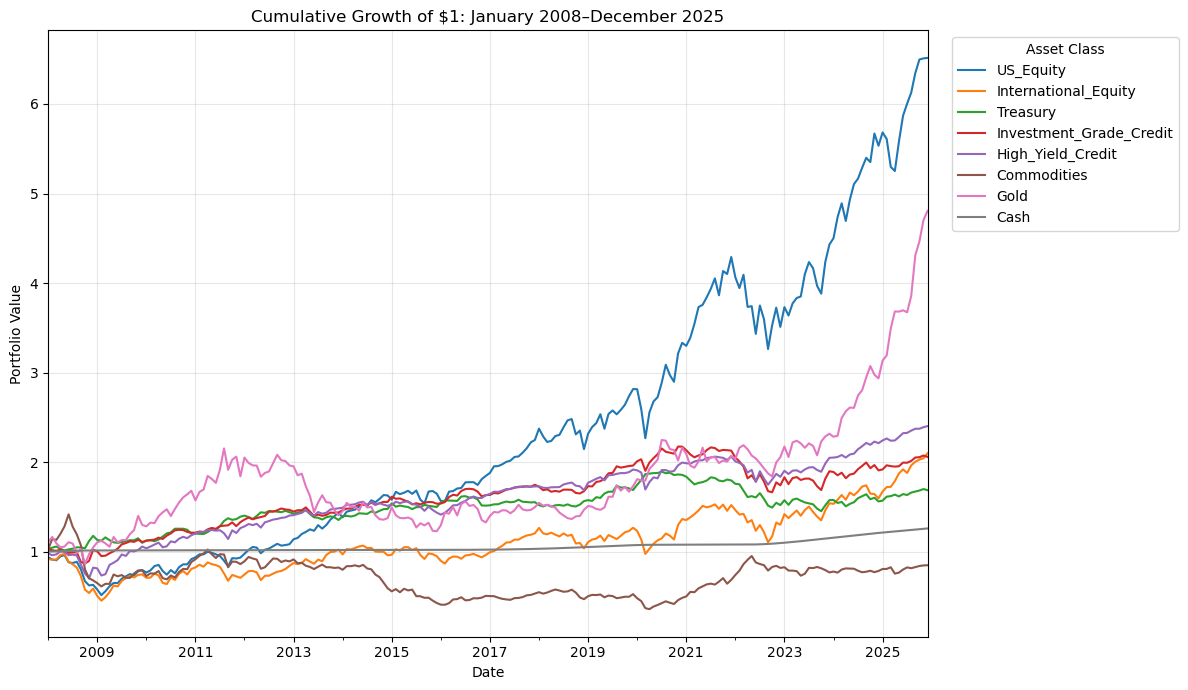

In [14]:
# ---------------------------------------------------------
# Plot cumulative asset returns
# ---------------------------------------------------------

cumulative_returns = (
    1 + all_asset_returns.fillna(0)
).cumprod()

fig, ax = plt.subplots(figsize=(12, 7))

cumulative_returns.plot(
    ax=ax,
    linewidth=1.5,
)

ax.set_title(
    "Cumulative Growth of $1: January 2008–December 2025"
)
ax.set_xlabel("Date")
ax.set_ylabel("Portfolio Value")
ax.grid(alpha=0.3)
ax.legend(
    title="Asset Class",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()

In [15]:
final_values = cumulative_returns.iloc[-1]

total_returns = final_values - 1

asset_final_results = pd.DataFrame({
    "Final Value of $1": final_values,
    "Total Return": total_returns,
})

asset_final_results = asset_final_results.sort_values(
    by="Total Return",
    ascending=False,
)

asset_final_results.style.format({
    "Final Value of $1": "{:.3f}",
    "Total Return": "{:.2%}",
})

,Final Value of $1,Total Return
US_Equity,6.513,551.34%
Gold,4.806,380.61%
High_Yield_Credit,2.404,140.40%
International_Equity,2.101,110.08%
Investment_Grade_Credit,2.061,106.06%
Treasury,1.689,68.87%
Cash,1.262,26.18%
Commodities,0.851,-14.88%


In [16]:
# ---------------------------------------------------------
# Save the cleaned datasets
# ---------------------------------------------------------

monthly_prices.to_csv("monthly_asset_prices_2007_2025.csv")
all_asset_returns.to_csv("monthly_asset_returns_2008_2025.csv")
excess_returns.to_csv("monthly_excess_returns_2008_2025.csv")
tbill_yield.to_csv("three_month_tbill_yield_2007_2025.csv")

In [17]:
training_risky_returns = training_returns[
    [
        "US_Equity",
        "International_Equity",
        "Treasury",
        "Investment_Grade_Credit",
        "High_Yield_Credit",
        "Commodities",
        "Gold",
    ]
]

annualized_return = training_risky_returns.mean() * 12
annualized_volatility = training_risky_returns.std() * np.sqrt(12)
correlation_matrix = training_risky_returns.corr()
annualized_covariance = training_risky_returns.cov() * 12

risk_summary = pd.DataFrame({
    "Annualized Return": annualized_return,
    "Annualized Volatility": annualized_volatility,
})

risk_summary

,Annualized Return,Annualized Volatility
US_Equity,0.034631,0.189953
International_Equity,-0.003856,0.243445
Treasury,0.076524,0.075957
Investment_Grade_Credit,0.082132,0.101015
High_Yield_Credit,0.080916,0.161028
Commodities,0.008025,0.242895
Gold,0.158241,0.212883


In [18]:
correlation_matrix

,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold
US_Equity,1.000000,0.930203,-0.297205,0.346969,0.763094,0.640175,0.108335
International_Equity,0.930203,1.000000,-0.232239,0.438414,0.788379,0.668213,0.180274
Treasury,-0.297205,-0.232239,1.000000,0.416346,-0.140414,-0.261368,0.287039
Investment_Grade_Credit,0.346969,0.438414,0.416346,1.000000,0.692639,0.149493,0.184551
High_Yield_Credit,0.763094,0.788379,-0.140414,0.692639,1.000000,0.470954,0.084409
Commodities,0.640175,0.668213,-0.261368,0.149493,0.470954,1.000000,0.444050
Gold,0.108335,0.180274,0.287039,0.184551,0.084409,0.444050,1.000000


In [19]:
annualized_covariance

,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold
US_Equity,0.036082,0.043015,-0.004288,0.006658,0.023341,0.029537,0.004381
International_Equity,0.043015,0.059265,-0.004294,0.010781,0.030905,0.039512,0.009343
Treasury,-0.004288,-0.004294,0.005770,0.003195,-0.001717,-0.004822,0.004641
Investment_Grade_Credit,0.006658,0.010781,0.003195,0.010204,0.011267,0.003668,0.003969
High_Yield_Credit,0.023341,0.030905,-0.001717,0.011267,0.025930,0.018420,0.002894
Commodities,0.029537,0.039512,-0.004822,0.003668,0.018420,0.058998,0.022961
Gold,0.004381,0.009343,0.004641,0.003969,0.002894,0.022961,0.045319


## Equal Risk Contribution and Portfolio Weights

Equal Risk Contribution（ERC）的目标不是让所有资产拥有相同的资金权重，而是让每项资产对整个portfolio贡献相同的风险。

本项目包含7项风险资产，因此每项资产的目标risk contribution为：

$$
\frac{1}{7}=14.286\%.
$$

也就是说，我们希望：

$$
PRC_1=PRC_2=\cdots=PRC_7=14.286\%.
$$

这里需要区分两个概念：

- **Portfolio weight**：有多少资金投资在这项资产中；
- **Risk contribution**：这项资产贡献了多少portfolio risk。

因此：

$$
\text{Portfolio Weight}
\neq
\text{Risk Contribution}.
$$

例如，Treasury的波动率较低，所以需要分配更多资金，才能贡献与其他资产相同的风险。International Equity的波动率较高，而且与其他股票类资产相关性较高，因此只需要较低的资金权重，就可能贡献相同的风险。

### Portfolio Risk

假设portfolio weight vector为：

$$
\mathbf{w}
=
\begin{bmatrix}
w_1\\
w_2\\
\vdots\\
w_7
\end{bmatrix},
$$

资产收益的covariance matrix为：

$$
\Sigma.
$$

Portfolio variance为：

$$
\sigma_P^2
=
\mathbf{w}^{\top}\Sigma\mathbf{w}.
$$

Portfolio volatility为：

$$
\sigma_P
=
\sqrt{\mathbf{w}^{\top}\Sigma\mathbf{w}}.
$$

Covariance matrix同时包含：

1. 每项资产自身的variance；
2. 不同资产之间的covariance。

所以ERC weights不是只根据单个资产的volatility计算，而是根据完整的covariance matrix计算。

### Risk Contribution

资产 \(i\) 的marginal risk contribution为：

$$
MRC_i
=
\frac{(\Sigma\mathbf{w})_i}{\sigma_P}.
$$

它表示当资产 \(i\) 的weight稍微增加时，整个portfolio volatility会增加多少。

资产 \(i\) 的total risk contribution为：

$$
RC_i
=
w_iMRC_i.
$$

代入marginal risk contribution：

$$
RC_i
=
w_i
\frac{(\Sigma\mathbf{w})_i}{\sigma_P}.
$$

Percentage risk contribution为：

$$
PRC_i
=
\frac{RC_i}{\sigma_P}.
$$

因为：

$$
\sigma_P^2
=
\mathbf{w}^{\top}\Sigma\mathbf{w},
$$

所以：

$$
PRC_i
=
\frac{
w_i(\Sigma\mathbf{w})_i
}{
\mathbf{w}^{\top}\Sigma\mathbf{w}
}.
$$

### ERC Optimization

ERC要求每项资产的percentage risk contribution都等于：

$$
\frac{1}{7}.
$$

因此，优化器需要寻找一组weights，使：

$$
\frac{
w_i(\Sigma\mathbf{w})_i
}{
\mathbf{w}^{\top}\Sigma\mathbf{w}
}
=
\frac{1}{7},
\qquad i=1,\ldots,7.
$$

优化器最小化以下目标函数：

$$
\min_{\mathbf{w}}
\sum_{i=1}^{7}
\left[
\frac{
w_i(\Sigma\mathbf{w})_i
}{
\mathbf{w}^{\top}\Sigma\mathbf{w}
}
-
\frac{1}{7}
\right]^2.
$$

同时满足：

$$
\sum_{i=1}^{7}w_i=1,
$$

以及long-only constraint：

$$
w_i\geq0.
$$

优化器首先从equal weights开始。它计算当前每项资产的risk contribution：

- 如果某项资产的risk contribution高于14.286%，就降低它的weight；
- 如果某项资产的risk contribution低于14.286%，就提高它的weight；
- 重复调整，直到所有资产的risk contribution都接近14.286%。

使用2008–2012年的monthly returns估计covariance matrix后，得到以下ERC weights：

| Asset | Capital Weight | Target Risk Contribution |
|---|---:|---:|
| U.S. Equity | 9.05% | 14.286% |
| International Equity | 6.38% | 14.286% |
| U.S. Treasury | 42.36% | 14.286% |
| Investment-Grade Credit | 15.40% | 14.286% |
| High-Yield Credit | 9.88% | 14.286% |
| Commodities | 7.57% | 14.286% |
| Gold | 9.36% | 14.286% |

Treasury虽然获得了42.36%的capital weight，但它只贡献大约14.286%的portfolio risk。International Equity虽然只有6.38%的capital weight，也贡献大约14.286%的portfolio risk。

整个计算过程可以总结为：

$$
\text{Historical Returns}
\rightarrow
\text{Covariance Matrix}
\rightarrow
\text{Portfolio Risk}
\rightarrow
\text{Risk Contributions}
\rightarrow
\text{ERC Weights}.
$$

当前权重属于volatility-based ERC weights，不是直接根据Value at Risk计算的权重。VaR可以在后续作为portfolio risk management metric。

In [20]:
from scipy.optimize import minimize

In [21]:
def calculate_risk_contributions(
    weights,
    covariance_matrix
):
    """
    Calculate each asset's percentage contribution
    to total portfolio variance.
    """

    weights = np.asarray(weights)
    covariance_matrix = np.asarray(
        covariance_matrix
    )

    # Portfolio variance
    portfolio_variance = (
        weights.T
        @ covariance_matrix
        @ weights
    )

    # Marginal contribution to portfolio variance
    marginal_variance = (
        covariance_matrix @ weights
    )

    # Component contribution to portfolio variance
    component_variance = (
        weights * marginal_variance
    )

    # Percentage contribution to portfolio variance
    percentage_risk_contribution = (
        component_variance / portfolio_variance
    )

    return percentage_risk_contribution

In [22]:
def erc_objective(
    weights,
    covariance_matrix,
    target_risk_contribution
):
    """
    Minimize the squared differences between actual
    and target risk contributions.
    """

    actual_risk_contribution = (
        calculate_risk_contributions(
            weights,
            covariance_matrix
        )
    )

    return np.sum(
        (
            actual_risk_contribution
            - target_risk_contribution
        ) ** 2
    )

In [23]:
# Names of the seven risky assets
asset_names = (
    annualized_covariance.columns.tolist()
)

number_of_assets = len(asset_names)

# Equal target risk contribution: 1/7 per asset
target_risk_contribution = np.repeat(
    1 / number_of_assets,
    number_of_assets
)

# Use equal capital weights as the initial guess
initial_weights = np.repeat(
    1 / number_of_assets,
    number_of_assets
)

# Risky-asset weights must sum to 100%
constraints = {
    "type": "eq",
    "fun": lambda weights: np.sum(weights) - 1
}

# Long-only portfolio
bounds = [
    (0.0001, 1.0)
    for _ in range(number_of_assets)
]

erc_result = minimize(
    fun=erc_objective,
    x0=initial_weights,
    args=(
        annualized_covariance.values,
        target_risk_contribution
    ),
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={
        "maxiter": 10000,
        "ftol": 1e-12
    }
)

print("Optimization successful:", erc_result.success)
print("Solver message:", erc_result.message)
print("Objective value:", erc_result.fun)

Optimization successful: True
Solver message: Optimization terminated successfully
Objective value: 5.698905655163256e-14


/Users/songshiqin/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:353: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  warnings.warn("Values in x were outside bounds during a "


In [24]:
erc_risky_sleeve_weights = pd.Series(
    erc_result.x,
    index=asset_names,
    name="ERC_Weight"
)

erc_risky_sleeve_weights

US_Equity                 0.090508
International_Equity      0.063775
Treasury                  0.423578
Investment_Grade_Credit   0.154016
High_Yield_Credit         0.098785
Commodities               0.075748
Gold                      0.093591
Name: ERC_Weight, dtype: float64

In [25]:
# Calculate the actual percentage risk contribution
# produced by the optimized ERC weights

actual_risk_contribution = pd.Series(
    calculate_risk_contributions(
        erc_result.x,
        annualized_covariance.values
    ),
    index=asset_names,
    name="Risk_Contribution"
)

actual_risk_contribution

US_Equity                 0.142857
International_Equity      0.142857
Treasury                  0.142857
Investment_Grade_Credit   0.142857
High_Yield_Credit         0.142857
Commodities               0.142857
Gold                      0.142857
Name: Risk_Contribution, dtype: float64

In [26]:
erc_result.x

array([0.09050808, 0.06377491, 0.42357774, 0.15401553, 0.09878515,
       0.07574772, 0.09359087])

In [27]:
actual_risk_contribution.apply(
    lambda value: f"{value:.4%}"
)

US_Equity                  14.2857%
International_Equity       14.2857%
Treasury                   14.2857%
Investment_Grade_Credit    14.2857%
High_Yield_Credit          14.2857%
Commodities                14.2857%
Gold                       14.2857%
Name: Risk_Contribution, dtype: object

In [28]:
# ---------------------------------------------------------
# Add a fixed 5% cash allocation
# ---------------------------------------------------------

RISKY_ASSET_ALLOCATION = 0.95
CASH_ALLOCATION = 0.05

# Scale the seven risky-asset weights from 100% to 95%
strategic_risky_weights = (
    erc_risky_sleeve_weights
    * RISKY_ASSET_ALLOCATION
)

# Add the fixed 5% cash allocation
strategic_benchmark_weights = pd.concat([
    strategic_risky_weights,
    pd.Series({"Cash": CASH_ALLOCATION})
])

strategic_benchmark_weights.name = (
    "Strategic_Benchmark_Weight"
)

strategic_benchmark_weights

US_Equity                 0.085983
International_Equity      0.060586
Treasury                  0.402399
Investment_Grade_Credit   0.146315
High_Yield_Credit         0.093846
Commodities               0.071960
Gold                      0.088911
Cash                      0.050000
Name: Strategic_Benchmark_Weight, dtype: float64

In [29]:
strategic_benchmark_weights.sum()

1.0

In [30]:
strategic_benchmark_weights.apply(
    lambda value: f"{value:.2%}"
)

US_Equity                   8.60%
International_Equity        6.06%
Treasury                   40.24%
Investment_Grade_Credit    14.63%
High_Yield_Credit           9.38%
Commodities                 7.20%
Gold                        8.89%
Cash                        5.00%
Name: Strategic_Benchmark_Weight, dtype: object

In [31]:
# ---------------------------------------------------------
# Extract monthly asset returns for 2013
# ---------------------------------------------------------

returns_2013 = all_asset_returns.loc[
    "2013-01-01":"2013-12-31",
    strategic_benchmark_weights.index
].copy()

returns_2013

,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold,Cash
Date,,,,,,,,
2013-01-31,0.051190,0.037284,-0.012932,-0.012976,0.003428,0.024838,-0.005061,0.000058
2013-02-28,0.012759,-0.012885,0.011325,0.010761,0.009327,-0.047067,-0.050868,0.000058
2013-03-31,0.037971,0.013053,0.002868,-0.000467,0.008724,0.006635,0.009477,0.000083
2013-04-30,0.019213,0.050187,0.015252,0.021735,0.021180,-0.038081,-0.075623,0.000075
2013-05-31,0.023610,-0.030191,-0.031050,-0.032176,-0.025811,-0.015607,-0.061988,0.000050
2013-06-30,-0.013344,-0.026779,-0.025461,-0.032676,-0.016887,-0.028229,-0.110588,0.000033
2013-07-31,0.051677,0.053229,-0.003527,0.011060,0.028539,0.031835,0.074301,0.000042
2013-08-31,-0.029993,-0.019553,-0.014225,-0.009982,-0.012720,0.028153,0.052047,0.000033
2013-09-30,0.031647,0.078249,0.018462,0.007418,0.007813,-0.033758,-0.047838,0.000033


In [32]:
# ---------------------------------------------------------
# Calculate monthly strategic benchmark returns for 2013
# ---------------------------------------------------------

benchmark_returns_2013 = (
    returns_2013
    .mul(strategic_benchmark_weights, axis=1)
    .sum(axis=1)
)

benchmark_returns_2013.name = (
    "Strategic_Benchmark_Return"
)

benchmark_returns_2013

Date
2013-01-31    0.001220
2013-02-28   -0.000583
2013-03-31    0.007284
2013-04-30    0.006537
2013-05-31   -0.026056
2013-06-30   -0.031243
2013-07-31    0.019445
2013-08-31   -0.005487
2013-09-30    0.010029
2013-10-31    0.013763
2013-11-30   -0.005975
2013-12-31   -0.007116
Freq: M, Name: Strategic_Benchmark_Return, dtype: float64

In [33]:
benchmark_total_return_2013 = (
    (1 + benchmark_returns_2013).prod() - 1
)

print(
    "2013 Strategic Benchmark Return:",
    f"{benchmark_total_return_2013:.2%}"
)

2013 Strategic Benchmark Return: -1.93%


In [34]:
benchmark_cumulative_2013 = (
    1 + benchmark_returns_2013
).cumprod()

benchmark_cumulative_2013.name = (
    "Cumulative_Portfolio_Value"
)

benchmark_cumulative_2013

Date
2013-01-31   1.001220
2013-02-28   1.000636
2013-03-31   1.007925
2013-04-30   1.014514
2013-05-31   0.988080
2013-06-30   0.957209
2013-07-31   0.975822
2013-08-31   0.970468
2013-09-30   0.980200
2013-10-31   0.993691
2013-11-30   0.987753
2013-12-31   0.980724
Freq: M, Name: Cumulative_Portfolio_Value, dtype: float64

In [35]:
# ---------------------------------------------------------
# Function for calculating ERC benchmark weights
# ---------------------------------------------------------

def solve_erc_weights(
    covariance_matrix,
    risky_allocation=0.95,
    cash_allocation=0.05
):
    """
    Calculate Equal Risk Contribution weights for risky
    assets and then add a fixed cash allocation.
    """

    covariance_matrix = pd.DataFrame(
        covariance_matrix
    )

    asset_names_local = (
        covariance_matrix.columns.tolist()
    )

    number_of_assets = len(asset_names_local)

    # Equal target risk contribution
    target_risk_contribution = np.repeat(
        1 / number_of_assets,
        number_of_assets
    )

    # Equal weights as the initial guess
    initial_weights = np.repeat(
        1 / number_of_assets,
        number_of_assets
    )

    constraints = {
        "type": "eq",
        "fun": lambda weights: np.sum(weights) - 1
    }

    bounds = [
        (0.0001, 1.0)
        for _ in range(number_of_assets)
    ]

    result = minimize(
        fun=erc_objective,
        x0=initial_weights,
        args=(
            covariance_matrix.values,
            target_risk_contribution
        ),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={
            "maxiter": 10000,
            "ftol": 1e-12
        }
    )

    if not result.success:
        raise ValueError(
            f"ERC optimization failed: {result.message}"
        )

    # ERC weights within the risky sleeve
    risky_sleeve_weights = pd.Series(
        result.x,
        index=asset_names_local
    )

    # Scale risky assets from 100% to 95%
    total_portfolio_risky_weights = (
        risky_sleeve_weights * risky_allocation
    )

    # Add the fixed cash allocation
    complete_weights = pd.concat([
        total_portfolio_risky_weights,
        pd.Series({"Cash": cash_allocation})
    ])

    return complete_weights

In [36]:
# ---------------------------------------------------------
# Generate annual strategic benchmark weights
# ---------------------------------------------------------

BACKTEST_START_YEAR = 2013
BACKTEST_END_YEAR = 2025
ESTIMATION_WINDOW_YEARS = 5

annual_weight_list = []

for portfolio_year in range(
    BACKTEST_START_YEAR,
    BACKTEST_END_YEAR + 1
):
    # Example:
    # 2013 portfolio uses 2008-2012 returns.
    estimation_start_year = (
        portfolio_year - ESTIMATION_WINDOW_YEARS
    )

    estimation_end_year = portfolio_year - 1

    estimation_returns = all_asset_returns.loc[
        f"{estimation_start_year}-01-01":
        f"{estimation_end_year}-12-31",
        asset_names
    ].copy()

    # Confirm that exactly 60 monthly observations are used.
    if len(estimation_returns) != 60:
        raise ValueError(
            f"{portfolio_year}: expected 60 observations, "
            f"but received {len(estimation_returns)}"
        )

    if estimation_returns.isna().any().any():
        raise ValueError(
            f"{portfolio_year}: estimation data contains "
            "missing values"
        )

    annual_covariance = (
        estimation_returns.cov() * 12
    )

    weights_for_year = solve_erc_weights(
        covariance_matrix=annual_covariance,
        risky_allocation=0.95,
        cash_allocation=0.05
    )

    weights_for_year.name = portfolio_year

    annual_weight_list.append(
        weights_for_year
    )

annual_benchmark_weights = pd.DataFrame(
    annual_weight_list
)

annual_benchmark_weights.index.name = "Portfolio_Year"

annual_benchmark_weights

/Users/songshiqin/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:353: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  warnings.warn("Values in x were outside bounds during a "
/Users/songshiqin/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:353: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  warnings.warn("Values in x were outside bounds during a "
/Users/songshiqin/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:353: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  warnings.warn("Values in x were outside bounds during a "
/Users/songshiqin/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:353: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  warnings.warn("Values in x were outside bounds during a "
/Users/songshiqin/anaconda3/lib/pyth

,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold,Cash
Portfolio_Year,,,,,,,,
2013,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
2014,0.080330,0.057680,0.372227,0.175749,0.110194,0.072150,0.081670,0.050000
2015,0.094127,0.062111,0.387405,0.176018,0.108495,0.059074,0.062771,0.050000
2016,0.101084,0.069746,0.355896,0.179108,0.114991,0.069941,0.059234,0.050000
2017,0.118746,0.076508,0.301153,0.172675,0.136614,0.080071,0.064233,0.050000
2018,0.125831,0.084604,0.266578,0.172193,0.142019,0.090074,0.068700,0.050000
2019,0.103581,0.081077,0.295446,0.169117,0.146303,0.078456,0.076021,0.050000
2020,0.094483,0.083654,0.310180,0.153077,0.145357,0.085885,0.077365,0.050000
2021,0.070736,0.070071,0.417367,0.118019,0.120645,0.073642,0.079521,0.050000


In [37]:
annual_benchmark_weights.sum(axis=1)

Portfolio_Year
2013   1.000000
2014   1.000000
2015   1.000000
2016   1.000000
2017   1.000000
2018   1.000000
2019   1.000000
2020   1.000000
2021   1.000000
2022   1.000000
2023   1.000000
2024   1.000000
2025   1.000000
dtype: float64

In [38]:
# ---------------------------------------------------------
# Expand annual weights into monthly weights
# ---------------------------------------------------------

benchmark_return_data = all_asset_returns.loc[
    "2013-01-01":"2025-12-31",
    annual_benchmark_weights.columns
].copy()

monthly_benchmark_weights = pd.DataFrame(
    index=benchmark_return_data.index,
    columns=annual_benchmark_weights.columns,
    dtype=float
)

for date in monthly_benchmark_weights.index:
    portfolio_year = date.year

    monthly_benchmark_weights.loc[date] = (
        annual_benchmark_weights.loc[
            portfolio_year
        ]
    )

monthly_benchmark_weights.head(15)

,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold,Cash
Date,,,,,,,,
2013-01-31,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
2013-02-28,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
2013-03-31,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
2013-04-30,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
2013-05-31,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
2013-06-30,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
2013-07-31,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
2013-08-31,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
2013-09-30,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000


In [39]:
monthly_benchmark_weights.loc[
    "2013-12-31":"2014-01-31"
].style.format("{:.2%}")

,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold,Cash
Date,,,,,,,,
2013-12-31 00:00:00,8.60%,6.06%,40.24%,14.63%,9.38%,7.20%,8.89%,5.00%
2014-01-31 00:00:00,8.03%,5.77%,37.22%,17.57%,11.02%,7.21%,8.17%,5.00%


In [40]:
# ---------------------------------------------------------
# Calculate monthly return contributions
# ---------------------------------------------------------

monthly_asset_contributions = (
    benchmark_return_data
    * monthly_benchmark_weights
)

monthly_asset_contributions.head()

,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold,Cash
Date,,,,,,,,
2013-01-31,0.004401,0.002259,-0.005204,-0.001899,0.000322,0.001787,-0.000450,0.000003
2013-02-28,0.001097,-0.000781,0.004557,0.001574,0.000875,-0.003387,-0.004523,0.000003
2013-03-31,0.003265,0.000791,0.001154,-0.000068,0.000819,0.000477,0.000843,0.000004
2013-04-30,0.001652,0.003041,0.006137,0.003180,0.001988,-0.002740,-0.006724,0.000004
2013-05-31,0.002030,-0.001829,-0.012494,-0.004708,-0.002422,-0.001123,-0.005511,0.000002


In [41]:
# ---------------------------------------------------------
# Calculate monthly benchmark returns
# ---------------------------------------------------------

strategic_benchmark_returns = (
    monthly_asset_contributions.sum(axis=1)
)

strategic_benchmark_returns.name = (
    "Strategic_ERC_Benchmark"
)

strategic_benchmark_returns.head()

Date
2013-01-31    0.001220
2013-02-28   -0.000583
2013-03-31    0.007284
2013-04-30    0.006537
2013-05-31   -0.026056
Freq: M, Name: Strategic_ERC_Benchmark, dtype: float64

In [42]:
# ---------------------------------------------------------
# Calculate cumulative portfolio value
# ---------------------------------------------------------

strategic_benchmark_cumulative = (
    1 + strategic_benchmark_returns
).cumprod()

strategic_benchmark_cumulative.name = (
    "Strategic_ERC_Benchmark"
)

strategic_benchmark_cumulative

Date
2013-01-31   1.001220
2013-02-28   1.000636
2013-03-31   1.007925
2013-04-30   1.014514
2013-05-31   0.988080
               ...   
2025-08-31   1.639844
2025-09-30   1.686575
2025-10-31   1.706904
2025-11-30   1.731431
2025-12-31   1.737355
Freq: M, Name: Strategic_ERC_Benchmark, Length: 156, dtype: float64

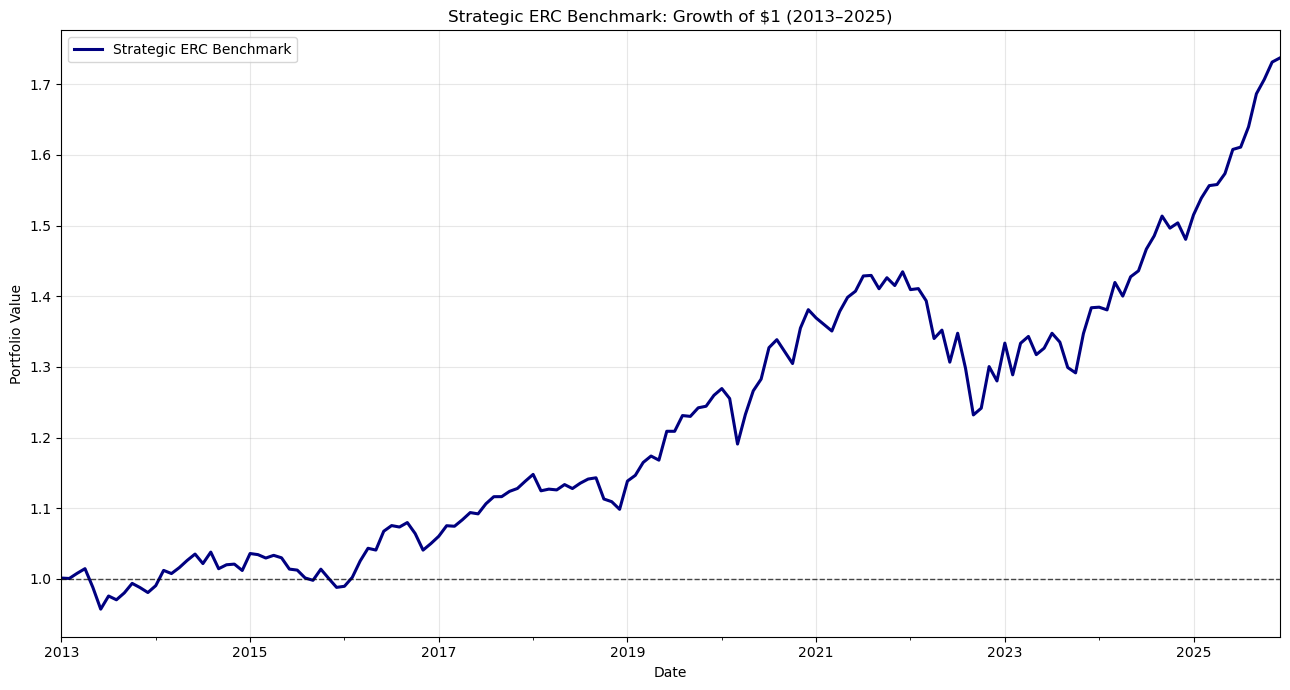

In [43]:
# ---------------------------------------------------------
# Plot the strategic benchmark cumulative return
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

strategic_benchmark_cumulative.plot(
    ax=ax,
    color="navy",
    linewidth=2.2,
    label="Strategic ERC Benchmark"
)

ax.axhline(
    y=1,
    color="black",
    linestyle="--",
    linewidth=1,
    alpha=0.7
)

ax.set_title(
    "Strategic ERC Benchmark: Growth of $1 "
    "(2013–2025)"
)
ax.set_xlabel("Date")
ax.set_ylabel("Portfolio Value")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [44]:
# ---------------------------------------------------------
# Calculate benchmark performance statistics
# ---------------------------------------------------------

number_of_months = len(
    strategic_benchmark_returns
)

number_of_years = number_of_months / 12

final_portfolio_value = (
    strategic_benchmark_cumulative.iloc[-1]
)

total_return = (
    final_portfolio_value - 1
)

cagr = (
    final_portfolio_value
    ** (1 / number_of_years)
    - 1
)

annualized_volatility = (
    strategic_benchmark_returns.std()
    * np.sqrt(12)
)

# Sharpe ratio using the monthly cash return
benchmark_excess_returns = (
    strategic_benchmark_returns
    - benchmark_return_data["Cash"]
)

sharpe_ratio = (
    benchmark_excess_returns.mean() * 12
) / (
    benchmark_excess_returns.std()
    * np.sqrt(12)
)

# Drawdown calculation
running_peak = (
    strategic_benchmark_cumulative.cummax()
)

drawdown = (
    strategic_benchmark_cumulative
    / running_peak
    - 1
)

maximum_drawdown = drawdown.min()

performance_summary = pd.Series({
    "Initial Portfolio Value": 1.0,
    "Final Portfolio Value": final_portfolio_value,
    "Total Return": total_return,
    "CAGR": cagr,
    "Annualized Volatility": annualized_volatility,
    "Sharpe Ratio": sharpe_ratio,
    "Maximum Drawdown": maximum_drawdown
})

performance_summary

Initial Portfolio Value    1.000000
Final Portfolio Value      1.737355
Total Return               0.737355
CAGR                       0.043405
Annualized Volatility      0.060215
Sharpe Ratio               0.468691
Maximum Drawdown          -0.141222
dtype: float64

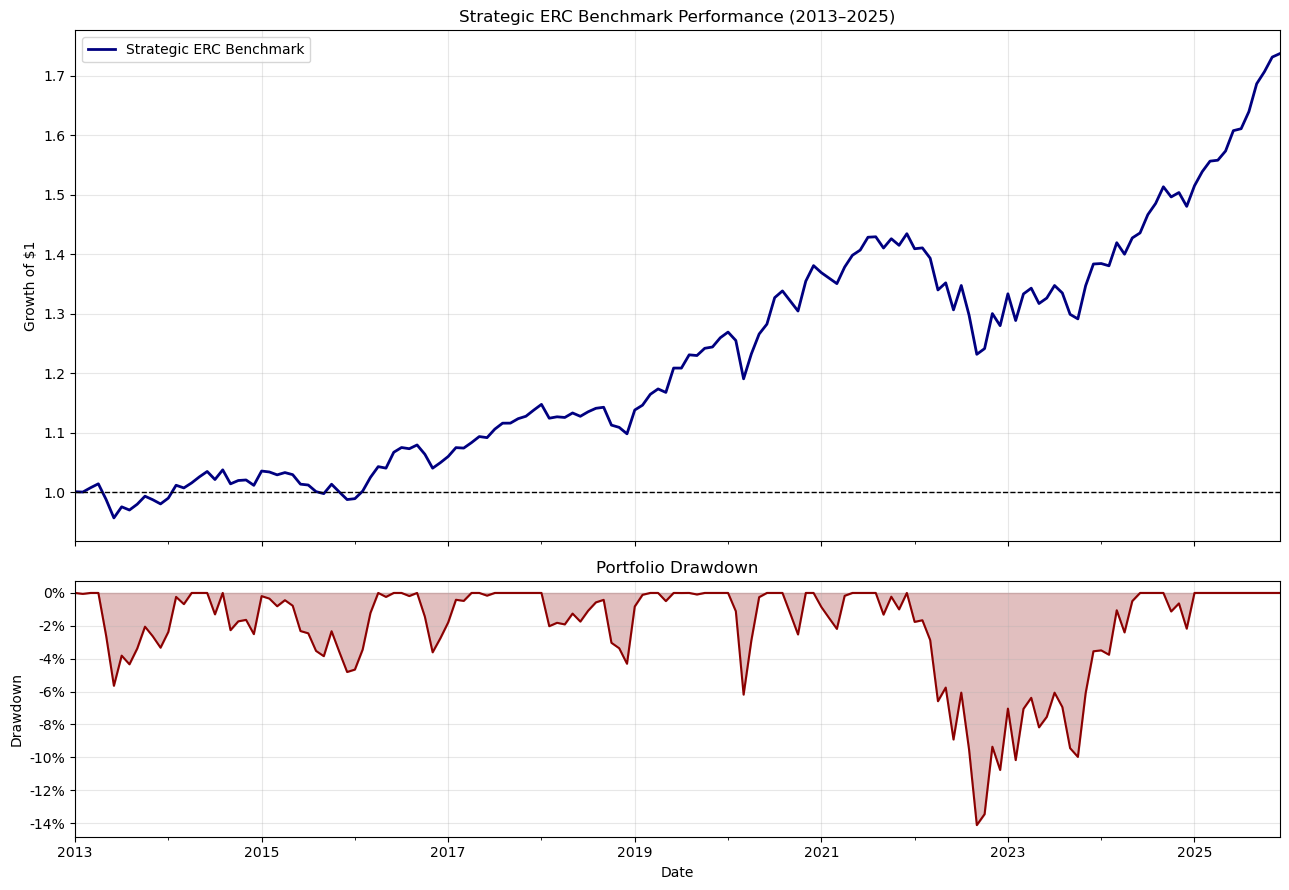

In [45]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(13, 9),
    sharex=True,
    gridspec_kw={
        "height_ratios": [2, 1]
    }
)

strategic_benchmark_cumulative.plot(
    ax=axes[0],
    color="navy",
    linewidth=2,
    label="Strategic ERC Benchmark"
)

axes[0].axhline(
    1,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[0].set_title(
    "Strategic ERC Benchmark Performance "
    "(2013–2025)"
)
axes[0].set_ylabel("Growth of $1")
axes[0].grid(alpha=0.3)
axes[0].legend()

drawdown.plot(
    ax=axes[1],
    color="darkred",
    linewidth=1.5
)

axes[1].fill_between(
    drawdown.index,
    drawdown.values,
    0,
    color="darkred",
    alpha=0.25
)

axes[1].set_title("Portfolio Drawdown")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Drawdown")
axes[1].yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda value, position: f"{value:.0%}"
    )
)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [46]:
strategic_benchmark_weights

US_Equity                 0.085983
International_Equity      0.060586
Treasury                  0.402399
Investment_Grade_Credit   0.146315
High_Yield_Credit         0.093846
Commodities               0.071960
Gold                      0.088911
Cash                      0.050000
Name: Strategic_Benchmark_Weight, dtype: float64

In [47]:
# ---------------------------------------------------------
# Fixed ERC benchmark
# Use the initial 2013 weights throughout 2013-2025
# ---------------------------------------------------------

fixed_benchmark_return_data = all_asset_returns.loc[
    "2013-01-01":"2025-12-31",
    strategic_benchmark_weights.index
].copy()

fixed_erc_returns = (
    fixed_benchmark_return_data
    .mul(strategic_benchmark_weights, axis=1)
    .sum(axis=1)
)

fixed_erc_returns.name = "Fixed_ERC_Benchmark"

fixed_erc_returns.head()

Date
2013-01-31    0.001220
2013-02-28   -0.000583
2013-03-31    0.007284
2013-04-30    0.006537
2013-05-31   -0.026056
Freq: M, Name: Fixed_ERC_Benchmark, dtype: float64

In [48]:
fixed_erc_cumulative = (
    1 + fixed_erc_returns
).cumprod()

fixed_erc_cumulative.name = (
    "Fixed ERC Benchmark"
)

In [49]:
strategic_benchmark_cumulative

Date
2013-01-31   1.001220
2013-02-28   1.000636
2013-03-31   1.007925
2013-04-30   1.014514
2013-05-31   0.988080
               ...   
2025-08-31   1.639844
2025-09-30   1.686575
2025-10-31   1.706904
2025-11-30   1.731431
2025-12-31   1.737355
Freq: M, Name: Strategic_ERC_Benchmark, Length: 156, dtype: float64

In [50]:
benchmark_comparison = pd.concat(
    [
        fixed_erc_cumulative,
        strategic_benchmark_cumulative.rename(
            "Rolling ERC Benchmark"
        )
    ],
    axis=1
)

benchmark_comparison.head()

,Fixed ERC Benchmark,Rolling ERC Benchmark
Date,,
2013-01-31,1.001220,1.001220
2013-02-28,1.000636,1.000636
2013-03-31,1.007925,1.007925
2013-04-30,1.014514,1.014514
2013-05-31,0.988080,0.988080


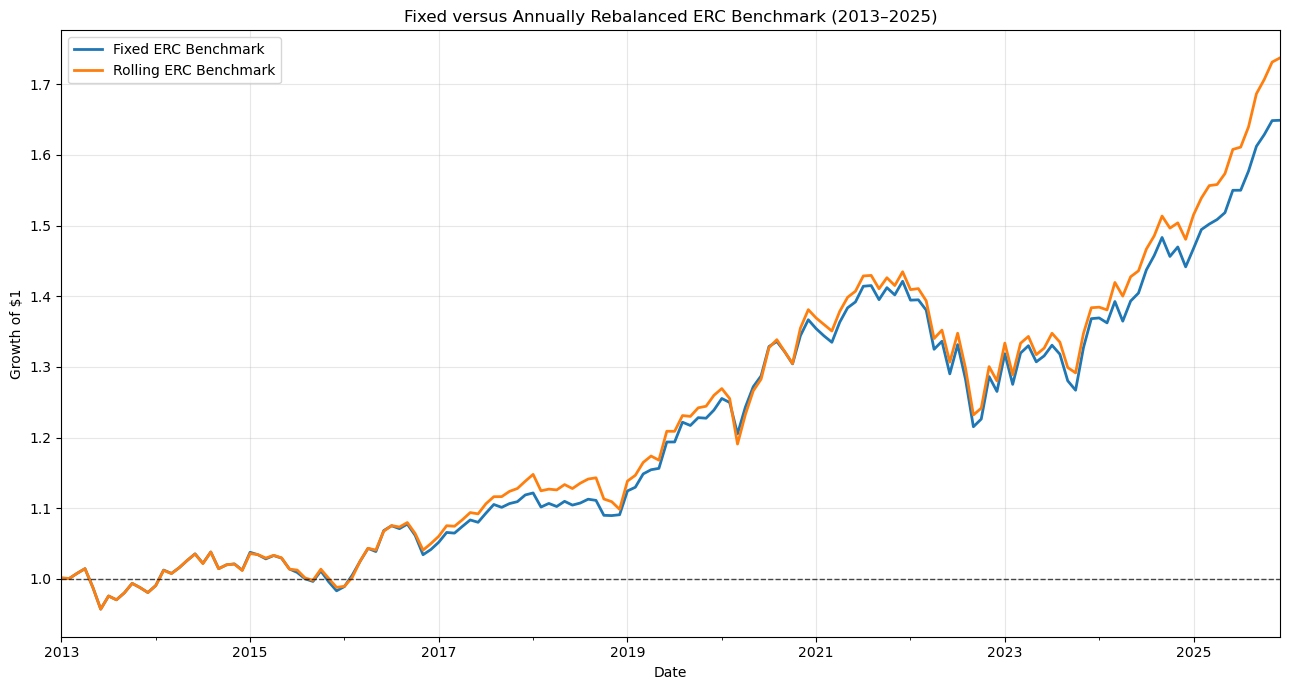

In [51]:
fig, ax = plt.subplots(figsize=(13, 7))

benchmark_comparison.plot(
    ax=ax,
    linewidth=2
)

ax.axhline(
    y=1,
    color="black",
    linestyle="--",
    linewidth=1,
    alpha=0.7
)

ax.set_title(
    "Fixed versus Annually Rebalanced ERC Benchmark "
    "(2013–2025)"
)
ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [52]:
comparison_final_value = (
    benchmark_comparison.iloc[-1]
)

comparison_total_return = (
    comparison_final_value - 1
)

comparison_results = pd.DataFrame({
    "Final Value of $1": comparison_final_value,
    "Total Return": comparison_total_return
})

comparison_results.style.format({
    "Final Value of $1": "${:.4f}",
    "Total Return": "{:.2%}"
})

,Final Value of $1,Total Return
Fixed ERC Benchmark,$1.6491,64.91%
Rolling ERC Benchmark,$1.7374,73.74%


In [53]:
def calculate_basic_performance(return_series):
    number_of_years = len(return_series) / 12

    final_value = (
        (1 + return_series).prod()
    )

    total_return = final_value - 1

    cagr = (
        final_value ** (1 / number_of_years) - 1
    )

    annualized_volatility = (
        return_series.std() * np.sqrt(12)
    )

    cumulative_value = (
        1 + return_series
    ).cumprod()

    drawdown = (
        cumulative_value
        / cumulative_value.cummax()
        - 1
    )

    maximum_drawdown = drawdown.min()

    return pd.Series({
        "Final Value": final_value,
        "Total Return": total_return,
        "CAGR": cagr,
        "Annualized Volatility": annualized_volatility,
        "Maximum Drawdown": maximum_drawdown
    })
benchmark_performance_comparison = pd.DataFrame({
    "Fixed ERC": calculate_basic_performance(
        fixed_erc_returns
    ),

    "Rolling ERC": calculate_basic_performance(
        strategic_benchmark_returns
    )
}).T

benchmark_performance_comparison.style.format({
    "Final Value": "${:.4f}",
    "Total Return": "{:.2%}",
    "CAGR": "{:.2%}",
    "Annualized Volatility": "{:.2%}",
    "Maximum Drawdown": "{:.2%}"
})

,Final Value,Total Return,CAGR,Annualized Volatility,Maximum Drawdown
Fixed ERC,$1.6491,64.91%,3.92%,5.89%,-14.49%
Rolling ERC,$1.7374,73.74%,4.34%,6.02%,-14.12%


In [54]:
# ---------------------------------------------------------
# Export Part 1 results for tactical allocation
# ---------------------------------------------------------

monthly_benchmark_weights.to_csv(
    "monthly_rolling_erc_weights_2013_2025.csv"
)

strategic_benchmark_returns.to_csv(
    "rolling_erc_returns_2013_2025.csv"
)

fixed_erc_returns.to_csv(
    "fixed_erc_returns_2013_2025.csv"
)

benchmark_return_data.to_csv(
    "monthly_all_asset_returns_2013_2025.csv"
)

print("Saved: monthly_rolling_erc_weights_2013_2025.csv")
print("Saved: rolling_erc_returns_2013_2025.csv")
print("Saved: fixed_erc_returns_2013_2025.csv")
print("Saved: monthly_all_asset_returns_2013_2025.csv")

Saved: monthly_rolling_erc_weights_2013_2025.csv
Saved: rolling_erc_returns_2013_2025.csv
Saved: fixed_erc_returns_2013_2025.csv
Saved: monthly_all_asset_returns_2013_2025.csv


In [55]:
print("Monthly Rolling ERC weight shape:")
print(monthly_benchmark_weights.shape)

print("\nFirst date:")
print(monthly_benchmark_weights.index.min())

print("\nLast date:")
print(monthly_benchmark_weights.index.max())

print("\nWeight sums:")
print(monthly_benchmark_weights.sum(axis=1).describe())

monthly_benchmark_weights.head()

Monthly Rolling ERC weight shape:
(156, 8)

First date:
2013-01-31 00:00:00

Last date:
2025-12-31 00:00:00

Weight sums:
count   156.000000
mean      1.000000
std       0.000000
min       1.000000
25%       1.000000
50%       1.000000
75%       1.000000
max       1.000000
dtype: float64


,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold,Cash
Date,,,,,,,,
2013-01-31,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
2013-02-28,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
2013-03-31,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
2013-04-30,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
2013-05-31,0.085983,0.060586,0.402399,0.146315,0.093846,0.071960,0.088911,0.050000
